# 1A. FNN - Hand-written MNIST
FNN baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy()
x_test = test.drop(columns="label").to_numpy()

print(x_train.shape, x_test.shape)

(60000, 784) (10000, 784)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Rescaling(1./255),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 878us/step - accuracy: 0.9269 - loss: 0.2567 - val_accuracy: 0.9589 - val_loss: 0.1377
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 825us/step - accuracy: 0.9662 - loss: 0.1143 - val_accuracy: 0.9684 - val_loss: 0.1018
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 820us/step - accuracy: 0.9764 - loss: 0.0776 - val_accuracy: 0.9735 - val_loss: 0.0836
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 818us/step - accuracy: 0.9827 - loss: 0.0566 - val_accuracy: 0.9733 - val_loss: 0.0806
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 819us/step - accuracy: 0.9866 - loss: 0.0432 - val_accuracy: 0.9782 - val_loss: 0.0687


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test loss: {loss:.4f}  test accuracy: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9688 - loss: 0.0675

118/313 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step - accuracy: 0.9693 - loss: 0.0955

238/313 ━━━━━━━━━━━━━━━━━━━━ 0s 424us/step - accuracy: 0.9764 - loss: 0.0734

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 442us/step - accuracy: 0.9782 - loss: 0.0687


test loss: 0.0687  test accuracy: 0.9782


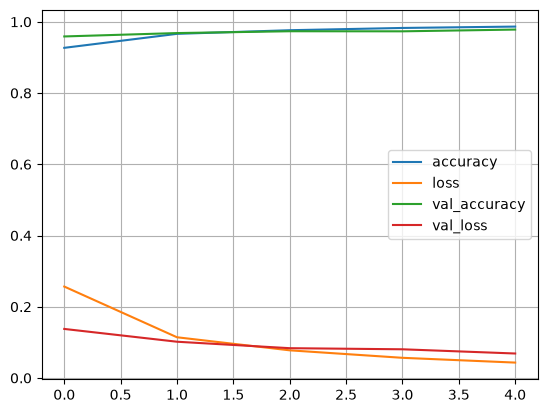

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()